# Cross-validation of mean estimators

Reading Material: Before addressing this exercise, we recommend that you study unsupervised foundations of mean-covariance learning.

Consider a univariate random variable 'X'  representing the daily linear returns of S&P500's adjusted closing price.
Our goal is to estimate the true mean of 'X'

Also, consider a dataset X1,......,Xt consisting of t = 501 daily linear returns obtained from January 1, 2024 to December 31, 2025.
The data is divided into two subsets for cross-validation: the first year serves as the estimation set and the second year serves as the test set

In this context, we will evaluate two scenario-probability distributions. In both cases, the scenarios are the elements of the estimation set 'T estimate' , but the assigned probabilities vary

for 'j = 1,2.  Finally, we define the two means associated with these scenario-probability distributions

In [29]:
import pandas as pd
from numpy import arange, ceil, exp, log, ones, sum
from yfinance import download
from matplotlib.pyplot import legend, plot, show, xticks

Using the YFinance package, download the adjusted closing prices for the S&P500 (SPX).
Compute the daily linear returns.
Split the data into estimation and test sets and plot the results.

In [30]:
# download SPY data
spxPrices = download('SPY', start='2024-01-01', end='2025-12-31')

# Extracting the closing prices
# Could use 'squeeze()' here to compress/convert the single-column dataframe into a clean Series
spxPrices = spxPrices['Close'].squeeze()
# printing values to console
spxPrices

[*********************100%***********************]  1 of 1 completed


Date
2024-01-02    458.809174
2024-01-03    455.062225
2024-01-04    453.596497
2024-01-05    454.217712
2024-01-08    460.702087
                 ...    
2025-12-23    684.323303
2025-12-24    686.730530
2025-12-26    686.660889
2025-12-29    684.213867
2025-12-30    683.378357
Name: SPY, Length: 501, dtype: float64

In [31]:
# Calculating the daily linear returns using percentage change from one days closing price to the next.
# Dropping the leading NaN value as the first value will be NaN, since there is no prior day to compare to.
x = spxPrices.pct_change().dropna()

# Extracting the length/number of returns contained in 'x'
t_bar = len(x)
t_bar

500

In [32]:
# verify my extracted data
print(type(x))              # Series or DataFrame?
print(x.index)               # is it a DatetimeIndex?
print(isinstance(x.index, pd.DatetimeIndex))
print(x.shape)                # (n,) for Series vs (n,1) for DataFrame

# split into estimation set (2024) and test set (2025)
# Pandas Series that is indexed by date, se we have sliced by date here

# used to fit estimate the model
# if use 'squeeze()' when extracting the Close prices then '.loc[]' would not be required here
x_estimation = x.loc['2024']
t_estim = len(x_estimation)
print('t_estim = ', t_estim)

# used to check how well what the model was trained on holds up on data that the model has NOT seen.
# if use 'squeeze()' when extracting the Close prices then '.loc[]' would not be required here
x_test = x.loc['2025']
t_test = len(x_test)
print('t_test = ', t_test)

# quick sanity check
print(len(x_estimation), len(x_test))
print(x_estimation.index.min(), x_estimation.index.max())
print(x_test.index.min(), x_test.index.max())

<class 'pandas.Series'>
DatetimeIndex(['2024-01-03', '2024-01-04', '2024-01-05', '2024-01-08',
               '2024-01-09', '2024-01-10', '2024-01-11', '2024-01-12',
               '2024-01-16', '2024-01-17',
               ...
               '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19',
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-26',
               '2025-12-29', '2025-12-30'],
              dtype='datetime64[s]', name='Date', length=500, freq=None)
True
(500,)
t_estim =  251
t_test =  249
251 249
2024-01-03 00:00:00 2024-12-31 00:00:00
2025-01-02 00:00:00 2025-12-30 00:00:00


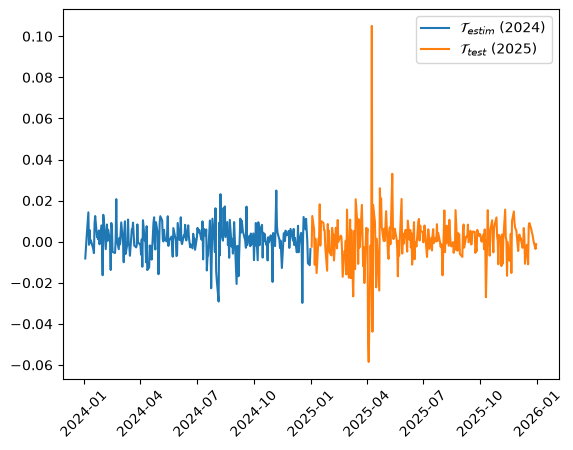

In [34]:
# Plot estimation and test sets
plot(x_estimation.index, x_estimation.values, label=r'$\mathcal{T}_{estim}$ (2024)')
plot(x_test.index, x_test.values, label=r'$\mathcal{T}_{test}$ (2025)')
legend()
xticks(rotation=45)
show()

In [ ]:
# Achieved up to this point
# 1. Downloaded daily SPY price data
# 2. Feature Extraction - pulling out the 'Close' prices
# 3. Linear Simple Return calculation using pct_change()
# 4. Data Validation with type/shape/index
# 5. Train/Test split
# 6. Visualisation of both sets

In [ ]:
# Next Steps
# The task is asking you to treat each of the 𝑡_𝑒𝑠𝑡𝑖𝑚 historical daily returns in x_estimation as equally likely
# — i.e. assign each observed return a probability of 1/𝑡_𝑒𝑠𝑡𝑖𝑚
# This is the "empirical" or "historical" distribution: you're not assuming any parametric model,
# you're just saying "the past 2024 daily returns are my scenario distribution, each equally weighted."
# The sample mean under uniform probabilities is just the familiar arithmetic average:

In [35]:
# uniform probabilities
# creating an array of length 't_estim' filled entirely with 1's
# Dividing he whole array by 't_estim' turn every 1 into '1/𝑡_𝑒𝑠𝑡𝑖𝑚'
# so p_1 now becomes an array like [1/251, 1/251, ..., 1/251] one probability value per day, equal in size.
# considering every historical daily return equally likely.  Or as the text says 'uniform probabilities'
p_1 = ones(t_estim) / t_estim

# Verify the shape of each array before multiplying they need to match, then this is a red flag
print(p_1.shape, x_estimation.shape)

# Sample mean = probability-weighted sum of returns
# x_estimation.values turns the Pandas series into a plain NumPy array of the actual daily return values
# p_1 * x_estimation.values multiplies element-wise each prob by its corresponding return
# since every probability is '1/𝑡_𝑒𝑠𝑡𝑖𝑚', this just scales each return down by '1/𝑡_𝑒𝑠𝑡𝑖𝑚'
# sum() adds all those scaled values together, which is actually the arithmetic mean of the 2024 returns (*weighted sum)
mu_hat_1 = sum(p_1 * x_estimation.values)
# printing the mean after rounding it to 3 decimal places
print('mu_hat_1 = ', mu_hat_1.round(3))

(251,) (251,)
mu_hat_1 =  0.001


In [37]:
# Just verifying that this gives me the same value as x_estimation.mean()
x_estimation.mean().round(3)


np.float64(0.001)